In [9]:
import pandas as pd
import math
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# 1. Load the cleaned dataset
df = pd.read_csv('../data/processed/cleaned_vehicles.csv')

# 2. Verify the load
print("Dataset Dimensions:", df.shape)
display(df.head())

Dataset Dimensions: (205, 26)


,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,wheel-base,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling
0,13495.0,27.0,21.0,5000.0,111.0,9.0,2.68,3.47,mpfi,130.0,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,115.0,3.0
1,16500.0,27.0,21.0,5000.0,111.0,9.0,2.68,3.47,mpfi,130.0,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,115.0,3.0
2,16500.0,26.0,19.0,5000.0,154.0,9.0,3.47,2.68,mpfi,152.0,...,94.5,front,rwd,hatchback,2.0,std,gas,alfa-romero,115.0,1.0
3,13950.0,30.0,24.0,5500.0,102.0,10.0,3.40,3.19,mpfi,109.0,...,99.8,front,fwd,sedan,4.0,std,gas,audi,164.0,2.0
4,17450.0,22.0,18.0,5500.0,115.0,8.0,3.40,3.19,mpfi,136.0,...,99.4,front,4wd,sedan,4.0,std,gas,audi,164.0,2.0


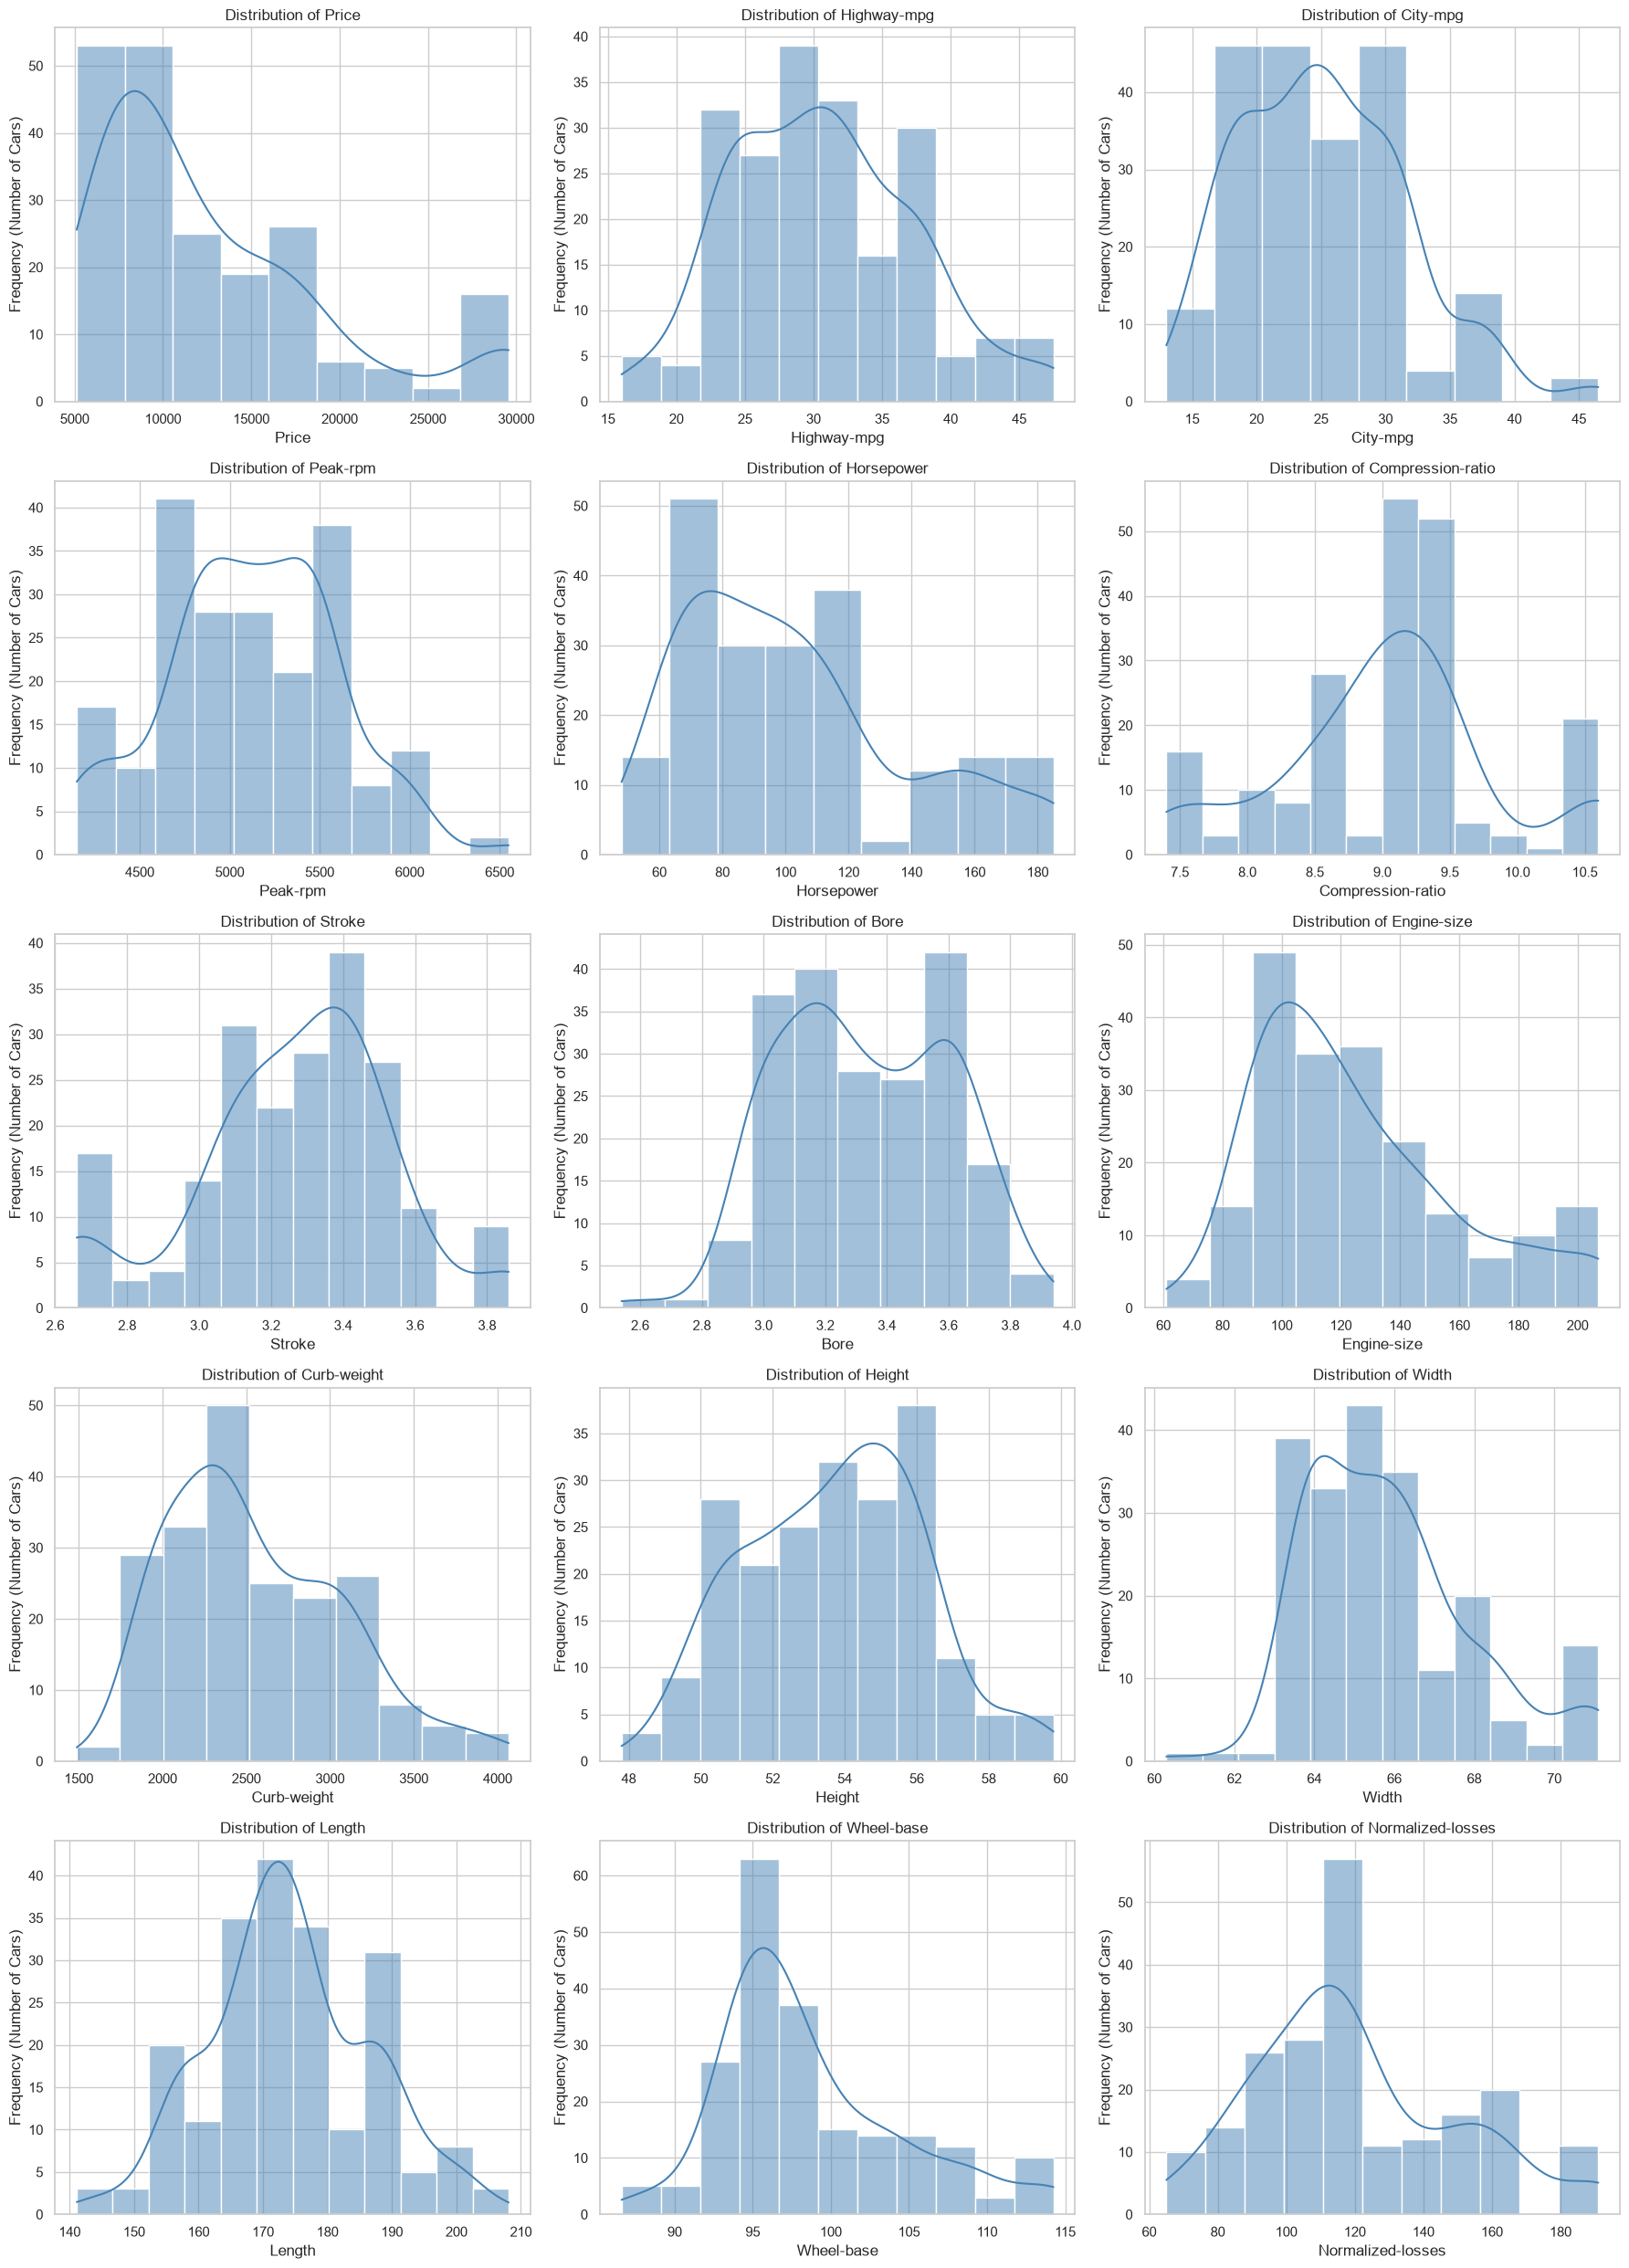

In [12]:
# Visualize the distribution of all numerical columns in the dataset
#===================================================================

# Set the visual style
sns.set_theme(style="whitegrid")

# 1. Isolate all numerical columns and convert to a standard Python list
all_numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

# 2. Define the discrete columns that shouldn't have KDE curves
discrete_cols = ['num-of-doors', 'symboling', 'num-of-cylinders']

# 3. Filter them out to create a list of strictly continuous columns
continuous_columns = [col for col in all_numeric_columns if col not in discrete_cols]

# Define the grid structure (3 columns wide)
num_cols = 3
# Calculate required rows based on the NEW filtered list
num_rows = math.ceil(len(continuous_columns) / num_cols)

# Set up a dynamic canvas
plt.figure(figsize=(18, 5 * num_rows))

# Loop through ONLY the truly continuous columns
for i, col in enumerate(continuous_columns, 1):
    plt.subplot(num_rows, num_cols, i) 
    
    # Generate the histogram using auto bins
    sns.histplot(df[col], kde=True, bins='auto', color='steelblue')
    
    # Add clear labels
    plt.title(f'Distribution of {col.capitalize()}')
    plt.xlabel(col.capitalize())
    plt.ylabel('Frequency (Number of Cars)')

plt.tight_layout()

# Save and show
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/continuous_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
#Analysis of the distribution of categorical columns in the dataset
# Set the visual style for all Seaborn plots
sns.set_theme(style="whitegrid")

# Define the categorical columns we want to examine
columns_to_plot = ['drive-wheels', 'make', 'fuel-type']

# Set up a wide canvas (18 inches wide, 5 inches tall)
plt.figure(figsize=(18, 5))

# Loop through the columns and generate a chart for each
for i, col in enumerate(columns_to_plot, 1):
    # plt.subplot(rows, columns, position) - this places charts side-by-side
    plt.subplot(1, 3, i) 
    
    # Generate the histogram with a smoothed KDE line
    sns.countplot(data=df, x=col, hue=col, palette='viridis', legend=False)
    
    # Add clear labels
    plt.title(f'Count of Cars by {col.capitalize()}')
    plt.xlabel(col.capitalize())
    plt.ylabel('Frequency (Number of Cars)')

# Automatically adjust spacing so text doesn't overlap
plt.tight_layout()
plt.show()

C:\Users\Laptop World\AppData\Local\Temp\ipykernel_24076\2485143324.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include=['object']).columns.tolist()


--- Unique Categories per Column ---
symboling: 6 categories
drive-wheels: 3 categories
body-style: 5 categories
num-of-doors: 2 categories
make: 22 categories
fuel-system: 8 categories
engine-type: 7 categories
fuel-type: 2 categories
aspiration: 2 categories
engine-location: 2 categories
num-of-cylinders: 1 categories


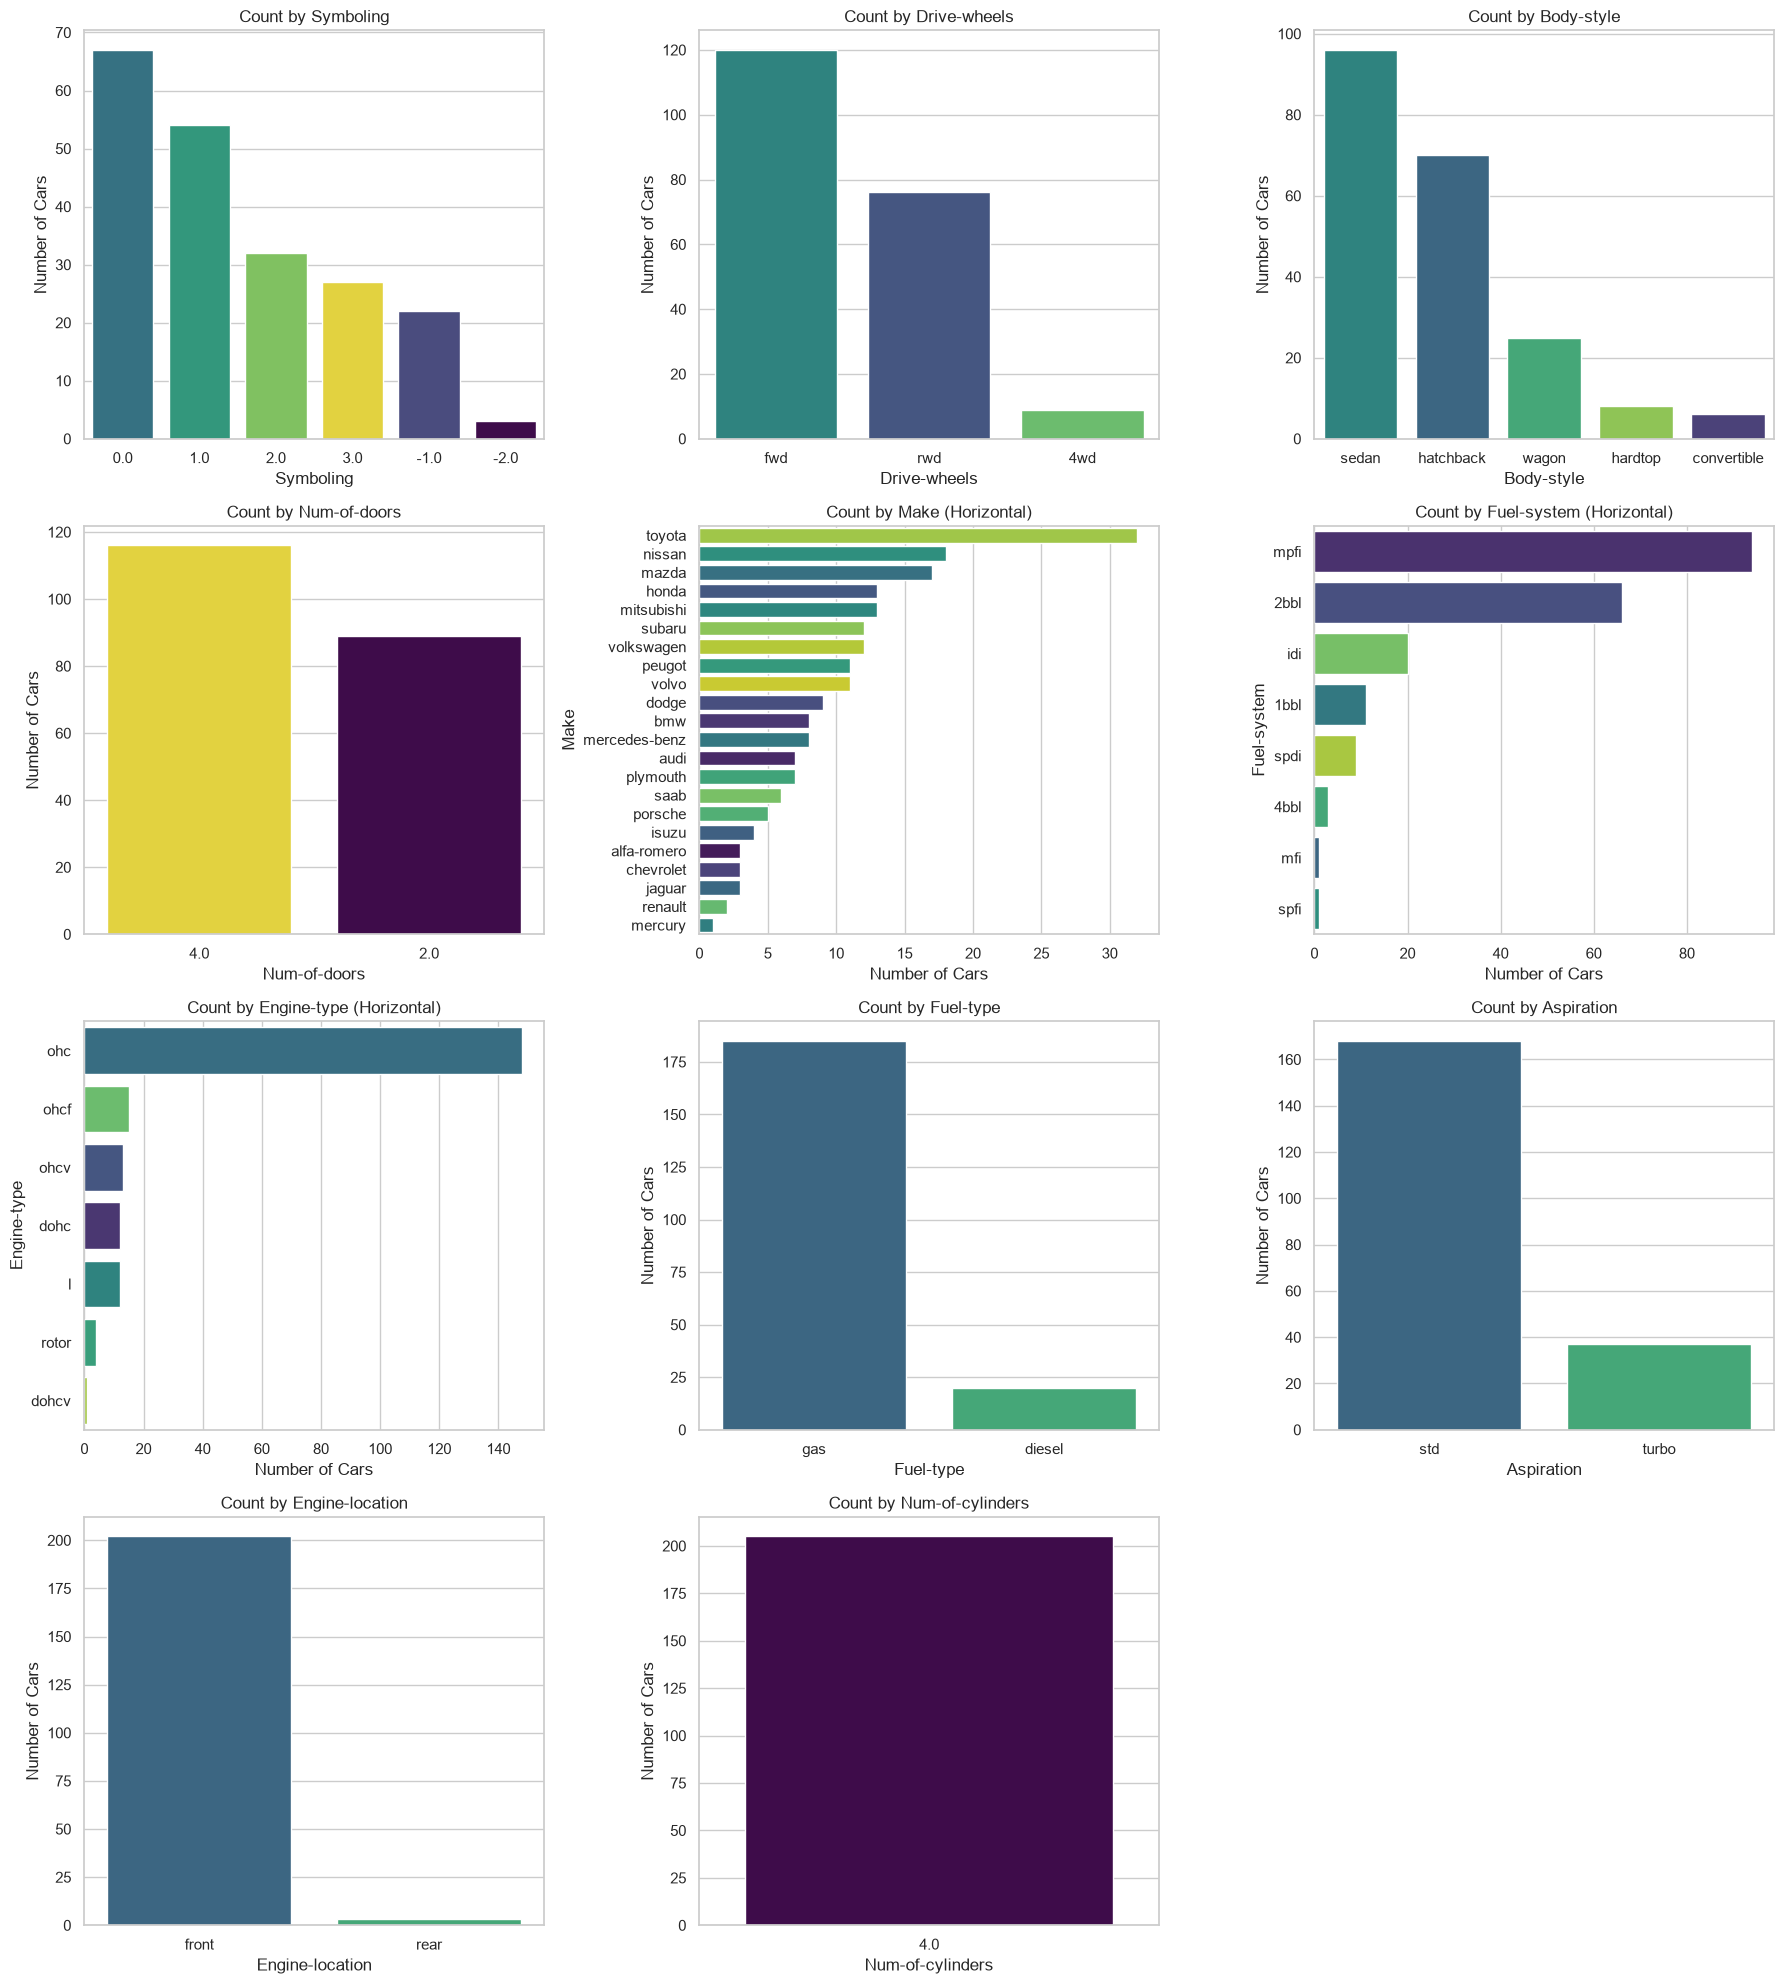

In [ ]:
# Visualize the distribution of all categorical and discrete columns in the dataset

# 1. Gather all categorical and discrete columns
# Get standard text columns and add our discrete numerical columns from earlier
object_cols = df.select_dtypes(include=['str']).columns.tolist()
discrete_cols = ['num-of-doors', 'symboling', 'num-of-cylinders']
all_categorical_cols = list(set(object_cols + discrete_cols))

# 2. Diagnostic Print: Count unique categories
print("--- Unique Categories per Column ---")
for col in all_categorical_cols:
    unique_count = df[col].nunique()
    print(f"{col}: {unique_count} categories")

# 3. Dynamic Visualizations
sns.set_theme(style="whitegrid")
num_cols = 3
num_rows = math.ceil(len(all_categorical_cols) / num_cols)

# Set canvas size
plt.figure(figsize=(18, 5 * num_rows))

for i, col in enumerate(all_categorical_cols, 1):
    plt.subplot(num_rows, num_cols, i)
    
    unique_count = df[col].nunique()
    
    # Sort the bars by count for better readability
    order = df[col].value_counts().index
    
    # Conditional logic based on your cardinaltiy observation
    if unique_count >= 7:
        # Flip to horizontal (y=col) for high-cardinality columns like 'make'
        sns.countplot(data=df, y=col, hue=col, palette='viridis', legend=False, order=order)
        plt.title(f'Count by {col.capitalize()} (Horizontal)')
        plt.xlabel('Number of Cars')
        plt.ylabel(col.capitalize())
    else:
        # Keep vertical (x=col) for low-cardinality columns like 'fuel-type'
        sns.countplot(data=df, x=col, hue=col, palette='viridis', legend=False, order=order)
        plt.title(f'Count by {col.capitalize()}')
        plt.xlabel(col.capitalize())
        plt.ylabel('Number of Cars')

plt.tight_layout()

# Save and render
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/categorical_distributions.png', dpi=300, bbox_inches='tight')
plt.show()